In [ ]:
# MTS Table 1 API - JSON Format
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

c:\Users\V_MILHAU\.conda\envs\finenv\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
plt.rcParams.update({'axes.grid': True})

In [3]:
baseUrl = "https://api.fiscaldata.treasury.gov/services/api/fiscal_service"
endpoint = "/v1/accounting/od/auctions_query"
url = f"{baseUrl}{endpoint}"

params = {
    "sort": "-record_date",
    "format": "json",
    "page[size]": 1000,
}

all_rows = []
page = 1

while True:
    params["page[number]"] = page
    response = requests.get(url, params=params)
    response.raise_for_status()
    data = response.json()

    rows = data.get("data", [])
    if not rows:
        break

    all_rows.extend(rows)

    total_pages = data['meta']['total-pages']
    print(f"Page {page}/{total_pages}")

    if page >= total_pages:
        break

    page += 1

raw = pd.DataFrame(all_rows)

Page 1/12
Page 2/12
Page 3/12
Page 4/12
Page 5/12
Page 6/12
Page 7/12
Page 8/12
Page 9/12
Page 10/12
Page 11/12
Page 12/12


In [4]:
raw

,record_date,cusip,security_type,security_term,auction_date,issue_date,maturity_date,price_per100,accrued_int_per100,accrued_int_per1000,...,total_tendered,treas_retail_accepted,treas_retail_tenders_accepted,unadj_accrued_int_per1000,unadj_price,xml_filenm_announcemt,xml_filenm_comp_results,inflation_index_security,tint_cusip_1,tint_cusip_2
0,2026-07-07,912797VP9,Bill,17-Week,2026-07-01,2026-07-07,2026-11-03,98.745542,null,null,...,194417546900,316557800,Yes,null,null,A_20260630_1.xml,R_20260701_1.xml,No,null,null
1,2026-07-07,912797UW5,Bill,8-Week,2026-07-02,2026-07-07,2026-09-01,null,null,null,...,null,null,Yes,null,null,A_20260630_2.xml,null,No,null,null
2,2026-07-07,912797US4,Bill,4-Week,2026-07-02,2026-07-07,2026-08-04,null,null,null,...,null,null,Yes,null,null,A_20260630_3.xml,null,No,null,null
3,2026-07-02,912797VJ3,Bill,26-Week,2026-06-29,2026-07-02,2026-12-31,98.058667,null,null,...,208808185800,815600900,Yes,null,null,A_20260625_1.xml,R_20260629_2.xml,No,null,null
4,2026-07-02,912797TW7,Bill,6-Week,2026-06-30,2026-07-02,2026-08-13,99.573583,null,null,...,222048884500,779783700,Yes,null,null,A_20260625_3.xml,R_20260630_1.xml,No,null,null
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11020,1980-01-08,9127935W2,Bill,52-Week,1980-01-02,1980-01-08,1981-01-02,null,null,null,...,6329685000,null,null,null,null,null,null,No,null,null
11021,1980-01-03,9127933Y0,Bill,13-Week,1979-12-28,1980-01-03,1980-04-03,null,null,null,...,5371540000,null,null,null,null,null,null,No,null,null
11022,1980-01-03,9127934U7,Bill,26-Week,1979-12-28,1980-01-03,1980-07-03,null,null,null,...,5954350000,null,null,null,null,null,null,No,null,null
11023,1979-11-15,912827KC5,Note,10-Year,1979-10-31,1979-11-15,1989-11-15,null,null,0.0000000000,...,3818000000,null,null,null,null,null,null,No,null,null


In [5]:
raw['security_type'].unique()

array(['Bill', 'Note', 'Bond'], dtype=object)

In [6]:
raw['int_payment_frequency'].unique()

array(['None', 'Semi-Annual', 'Quarterly', 'null', 'Annual'], dtype=object)

In [7]:
date_cols = [k for k, v in data['meta']['dataTypes'].items() if v == 'DATE']
num_cols = [k for k, v in data['meta']['dataTypes'].items() if v == 'NUMBER']

In [8]:
df = (raw
      .replace({col: 'null' for col in num_cols}, np.nan)
      .astype({col: float for col in num_cols})
      .assign(**{col: lambda x, c=col: pd.to_datetime(x[c], format="%Y-%m-%d", errors='coerce') 
                 for col in date_cols})
      )

In [9]:
df

,record_date,cusip,security_type,security_term,auction_date,issue_date,maturity_date,price_per100,accrued_int_per100,accrued_int_per1000,...,total_tendered,treas_retail_accepted,treas_retail_tenders_accepted,unadj_accrued_int_per1000,unadj_price,xml_filenm_announcemt,xml_filenm_comp_results,inflation_index_security,tint_cusip_1,tint_cusip_2
0,2026-07-07,912797VP9,Bill,17-Week,2026-07-01,2026-07-07,2026-11-03,98.745542,NaN,NaN,...,1.944175e+11,316557800.0,Yes,NaN,NaN,A_20260630_1.xml,R_20260701_1.xml,No,null,null
1,2026-07-07,912797UW5,Bill,8-Week,2026-07-02,2026-07-07,2026-09-01,null,NaN,NaN,...,NaN,NaN,Yes,NaN,NaN,A_20260630_2.xml,null,No,null,null
2,2026-07-07,912797US4,Bill,4-Week,2026-07-02,2026-07-07,2026-08-04,null,NaN,NaN,...,NaN,NaN,Yes,NaN,NaN,A_20260630_3.xml,null,No,null,null
3,2026-07-02,912797VJ3,Bill,26-Week,2026-06-29,2026-07-02,2026-12-31,98.058667,NaN,NaN,...,2.088082e+11,815600900.0,Yes,NaN,NaN,A_20260625_1.xml,R_20260629_2.xml,No,null,null
4,2026-07-02,912797TW7,Bill,6-Week,2026-06-30,2026-07-02,2026-08-13,99.573583,NaN,NaN,...,2.220489e+11,779783700.0,Yes,NaN,NaN,A_20260625_3.xml,R_20260630_1.xml,No,null,null
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11020,1980-01-08,9127935W2,Bill,52-Week,1980-01-02,1980-01-08,1981-01-02,null,NaN,NaN,...,6.329685e+09,NaN,null,NaN,NaN,null,null,No,null,null
11021,1980-01-03,9127933Y0,Bill,13-Week,1979-12-28,1980-01-03,1980-04-03,null,NaN,NaN,...,5.371540e+09,NaN,null,NaN,NaN,null,null,No,null,null
11022,1980-01-03,9127934U7,Bill,26-Week,1979-12-28,1980-01-03,1980-07-03,null,NaN,NaN,...,5.954350e+09,NaN,null,NaN,NaN,null,null,No,null,null
11023,1979-11-15,912827KC5,Note,10-Year,1979-10-31,1979-11-15,1989-11-15,null,NaN,0.0,...,3.818000e+09,NaN,null,NaN,NaN,null,null,No,null,null


In [13]:
df[df['cusip'] == '912794TJ3']

,record_date,cusip,security_type,security_term,auction_date,issue_date,maturity_date,price_per100,accrued_int_per100,accrued_int_per1000,...,total_tendered,treas_retail_accepted,treas_retail_tenders_accepted,unadj_accrued_int_per1000,unadj_price,xml_filenm_announcemt,xml_filenm_comp_results,inflation_index_security,tint_cusip_1,tint_cusip_2
9439,1989-09-28,912794TJ3,Bill,13-Week,1989-09-25,1989-09-28,1989-12-28,null,NaN,NaN,...,2.390916e+10,NaN,null,NaN,NaN,null,null,No,null,null
9481,1989-06-29,912794TJ3,Bill,26-Week,1989-06-26,1989-06-29,1989-12-28,null,NaN,NaN,...,1.978944e+10,NaN,null,NaN,NaN,null,null,No,null,null


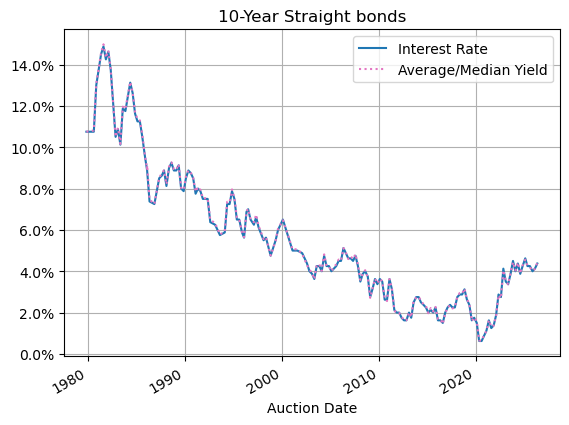

In [10]:
mask = (df['security_term'].str.contains('^(?:9|10)-Year*', regex=True)
        & (df['reopening'] == 'No')
        & (df['inflation_index_security'] == 'No')
        )

sub_df = df[mask].set_index('auction_date').sort_index()

fig,ax = plt.subplots()

labels = data['meta']['labels']

for col, style in [
    ('int_rate', {}),
    ('avg_med_yield', {'color': 'tab:pink', 'linestyle': ':'})
]:
    sub_df[col].plot(
        ax=ax,
        label=labels.get(col, col),
        **style
    )

ax.legend()

ax.set_xlabel(data['meta']['labels'][sub_df.index.name])

ax.set_title('10-Year Straight bonds')

ax.yaxis.set_major_formatter(PercentFormatter(100.))

plt.savefig('10-year.pdf')

In [12]:
df.to_csv(endpoint[1:].replace('/', '-') + '.csv')